<a href="https://colab.research.google.com/github/Anna-Zamriy/MN/blob/main/%D0%97%D0%B0%D0%BC%D1%80%D1%96%D0%B9_%D0%A4%D0%86%D0%A23_8_%D0%9B%D1%96%D0%BD%D1%96%D0%B9%D0%BD%D0%B0_%D1%80%D0%B5%D0%B3%D1%80%D0%B5%D1%81%D1%96%D1%8F_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Тренувальний ноутбук: лінійна регресія та регуляризація

**Курс:** Машинне навчання  
**Тема:** Linear Regression, Ridge, Lasso, Elastic Net

Цей ноутбук відповідає лекції про лінійну регресію та побудований як практичне продовження теоретичного матеріалу. У прикладах послідовно розглядаються проста й множинна лінійна регресія, метрики, залишки, недонавчання і перенавчання, L1/L2-регуляризація, Ridge, Lasso, Elastic Net, масштабування, крос-валідація, `GridSearchCV`, `Pipeline`, `ColumnTransformer` та навчальні криві.

У ноутбуці є два типи комірок:

- **Приклад** — готовий код, який потрібно виконати, проаналізувати та пояснити.
- **Самостійне завдання** — окрема кодова комірка з позначкою `TODO`. Її потрібно заповнити власноруч. Готового розв'язку в ноутбуці немає.

Рекомендація: виконувати комірки послідовно зверху вниз і після кожного блоку формулювати короткий висновок своїми словами.

## 0. Імпорт бібліотек і налаштування середовища

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)
from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate,
    GridSearchCV,
    learning_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('Середовище готове до роботи.')

Середовище готове до роботи.


## 1. Проста лінійна регресія

Для однієї ознаки модель має вигляд

$$
\hat y = b_0 + b_1x.
$$

Тут $b_0$ — вільний член, а $b_1$ показує, на скільки одиниць у середньому змінюється прогноз $\hat y$ при збільшенні $x$ на одну одиницю.

Нижче згенеруємо дані, у яких істинна залежність приблизно дорівнює $y=5+2.4x$, але спостереження містять випадковий шум.

Вільний член b0: 4.907
Коефіцієнт b1: 2.451


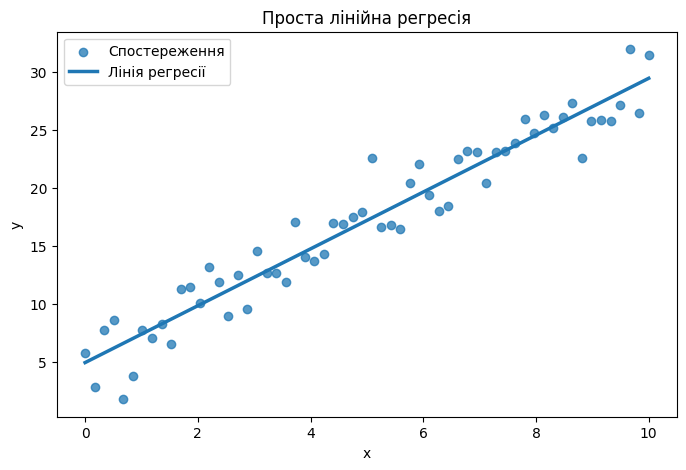

In [17]:
rng = np.random.default_rng(RANDOM_STATE)

X_simple = np.linspace(0, 10, 60).reshape(-1, 1)
y_simple = 5 + 2.4 * X_simple.ravel() + rng.normal(0, 2.5, size=len(X_simple))

simple_model = LinearRegression()
simple_model.fit(X_simple, y_simple)
y_simple_pred = simple_model.predict(X_simple)

print(f'Вільний член b0: {simple_model.intercept_:.3f}')
print(f'Коефіцієнт b1: {simple_model.coef_[0]:.3f}')

plt.figure(figsize=(8, 5))
plt.scatter(X_simple.ravel(), y_simple, alpha=0.75, label='Спостереження')
plt.plot(X_simple.ravel(), y_simple_pred, linewidth=2.5, label='Лінія регресії')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Проста лінійна регресія')
plt.legend()
plt.show()

**Що потрібно побачити.** Коефіцієнт нахилу має бути близьким до 2.4, але не обов'язково дорівнювати йому точно, оскільки дані містять шум. `fit()` оцінює параметри за навчальними даними, а `predict()` лише обчислює прогноз для заданих значень ознак.

### Самостійне завдання 1

1. Створіть новий масив `X_new` зі значеннями 2, 5 і 8.
2. Отримайте прогнози моделі.
3. Виведіть таблицю з колонками `x` та `prediction`.
4. Одним реченням поясніть зміст отриманого коефіцієнта `b1`.

In [ ]:
if "X" not in globals() or "y" not in globals():
    X = np.array([[1], [2], [3], [4], [5]], dtype=float)
    y = np.array([2.5, 4.1, 6.0, 8.2, 10.1], dtype=float)

if "model" not in globals():
    model = LinearRegression()
    model.fit(X, y)

# 1. Новий масив X_new зі значеннями 2, 5 і 8
X_new = np.array([[2], [5], [8]], dtype=float)

# 2. Прогнози моделі
predictions = model.predict(X_new)

# 3. Таблиця з колонками x та prediction
df_results = pd.DataFrame({
    "x": X_new.ravel(),
    "prediction": predictions.ravel()
})
print(df_results.to_string(index=False))

# 4. Пояснення коефіцієнта b1
b1 = float(np.ravel(model.coef_)[0])
print(f"\nКоефіцієнт b1 = {b1:.4f} показує, на скільки в середньому змінюється прогнозоване значення y при збільшенні x на 1 одиницю.")

  x  prediction
2.0        4.25
5.0       10.04
8.0       15.83

Коефіцієнт b1 = 1.9300 показує, на скільки в середньому змінюється прогнозоване значення y при збільшенні x на 1 одиницю.


## 2. Метод найменших квадратів і ручний розрахунок коефіцієнтів

Для простої регресії коефіцієнт нахилу можна обчислити без готової моделі:

$$
b_1 = \frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sum (x_i-\bar x)^2},
\qquad
b_0 = \bar y-b_1\bar x.
$$

Чисельник у формулі для $b_1$ відображає спільну зміну $x$ і $y$, а знаменник — варіативність самої ознаки $x$. Після знаходження нахилу вільний член підбирається так, щоб пряма проходила через точку $(\bar x, \bar y)$.

In [ ]:
x = np.array([1, 2, 3, 4, 5], dtype=float)
y = np.array([3.0, 5.2, 6.8, 9.1, 10.9])

x_bar = x.mean()
y_bar = y.mean()

b1_manual = ((x - x_bar) * (y - y_bar)).sum() / ((x - x_bar) ** 2).sum()
b0_manual = y_bar - b1_manual * x_bar

model_check = LinearRegression().fit(x.reshape(-1, 1), y)

print(f'Ручний розрахунок: b0={b0_manual:.4f}, b1={b1_manual:.4f}')
print(f'scikit-learn:     b0={model_check.intercept_:.4f}, b1={model_check.coef_[0]:.4f}')

Ручний розрахунок: b0=1.0900, b1=1.9700
scikit-learn:     b0=1.0900, b1=1.9700


### Самостійне завдання 2

Використайте масиви `x2 = [2, 4, 6, 8, 10]` та `y2 = [7, 11, 16, 19, 25]`. Власноруч обчисліть `b0` і `b1` за формулами, а потім перевірте результат за допомогою `LinearRegression`.

In [18]:
# 1. Задані масиви
x2 = np.array([2, 4, 6, 8, 10], dtype=float)
y2 = np.array([7, 11, 16, 19, 25], dtype=float)

# 2. Середні значення
x_mean = np.mean(x2)
y_mean = np.mean(y2)

# 3. Обчислення b1 та b0 власноруч
b1_manual = np.sum((x2 - x_mean) * (y2 - y_mean)) / np.sum((x2 - x_mean) ** 2)
b0_manual = y_mean - b1_manual * x_mean

# 4. Перевірка за допомогою LinearRegression зі sklearn
model = LinearRegression()
model.fit(x2.reshape(-1, 1), y2)

b1_sklearn = float(model.coef_[0])
b0_sklearn = float(model.intercept_)

print(f"Середні: x_mean = {x_mean}, y_mean = {y_mean}")
print(f"Власноруч: b0 = {b0_manual:.6f}, b1 = {b1_manual:.6f}")
print(f"sklearn:    b0 = {b0_sklearn:.6f}, b1 = {b1_sklearn:.6f}")
print(f"Різниця:    |db0| = {abs(b0_manual - b0_sklearn):.2e}, |db1| = {abs(b1_manual - b1_sklearn):.2e}")

Середні: x_mean = 6.0, y_mean = 15.6
Власноруч: b0 = 2.400000, b1 = 2.200000
sklearn:    b0 = 2.400000, b1 = 2.200000
Різниця:    |db0| = 1.78e-15, |db1| = 4.44e-16


## 3. Множинна лінійна регресія

У випадку кількох ознак модель має вигляд

$$
\hat y = b_0+b_1x_1+b_2x_2+\dots+b_px_p.
$$

Коефіцієнт $b_j$ інтерпретується як зміна прогнозу при збільшенні ознаки $x_j$ на одну одиницю **за інших рівних умов**, тобто при фіксованих значеннях інших ознак.

Для практики використаємо вбудований набір `diabetes`, тому ноутбук не потребує завантаження даних з Інтернету.

In [19]:
diabetes = load_diabetes(as_frame=True)
X = diabetes.data.copy()
y = diabetes.target.copy()

print('Розмір X:', X.shape)
print('Розмір y:', y.shape)
display(X.head())

Розмір X: (442, 10)
Розмір y: (442,)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [20]:
y

,target
0,151.0
1,75.0
2,141.0
3,206.0
4,135.0
...,...
437,178.0
438,104.0
439,132.0
440,220.0


In [21]:
multi_model = LinearRegression()
multi_model.fit(X, y)

coef_table = pd.DataFrame({
    'feature': X.columns,
    'coefficient': multi_model.coef_
}).sort_values('coefficient', key=np.abs, ascending=False)

display(coef_table)
print(f'Intercept: {multi_model.intercept_:.3f}')

,feature,coefficient
4,s1,-792.175639
8,s5,751.273700
2,bmi,519.845920
5,s2,476.739021
3,bp,324.384646
1,sex,-239.815644
7,s4,177.063238
6,s3,101.043268
9,s6,67.626692
0,age,-10.009866


Intercept: 152.133


Зверніть увагу: великий за модулем коефіцієнт не завжди означає, що ознака є «найважливішою». Порівняння коефіцієнтів залежить від масштабу ознак та їх взаємної кореляції.

## 4. Train/test та наївний baseline

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
)

baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

linear = LinearRegression()
linear.fit(X_train, y_train)
linear_pred = linear.predict(X_test)



`DummyRegressor` не використовує закономірності в ознаках і в цьому прикладі прогнозує середнє значення цільової змінної з train. Якщо реальна модель не перевершує такий baseline, необхідно переглянути ознаки, постановку задачі або сам алгоритм.

## 5. Метрики якості регресії

У лекції розглядалися MAE, MSE, RMSE та $R^2$. Вони відповідають на різні питання.

- **MAE** показує середню абсолютну величину помилки.
- **MSE** сильніше штрафує великі помилки через піднесення залишку до квадрата.
- **RMSE** є коренем з MSE і вимірюється в тих самих одиницях, що й цільова змінна.
- **$R^2$** порівнює модель із прогнозом середнім значенням цільової змінної. На нових даних він може бути від'ємним.

In [23]:
def regression_metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'MSE': mean_squared_error(y_true, y_pred),
        'RMSE': root_mean_squared_error(y_true, y_pred),
        'R2': r2_score(y_true, y_pred),
        'MAPE': (np.abs(y_true - y_pred) / y_true).mean() * 100
    }

metrics_baseline = regression_metrics(y_test, baseline_pred)
metrics_linear = regression_metrics(y_test, linear_pred)

pd.DataFrame([metrics_baseline, metrics_linear], index=['DummyRegressor', 'LinearRegression'])

,MAE,MSE,RMSE,R2,MAPE
DummyRegressor,64.006461,5361.533457,73.222493,-0.011963,62.791796
LinearRegression,42.794095,2900.193628,53.853446,0.452603,37.499826


### Самостійне завдання 3

Обчисліть MAE, RMSE і $R^2$ окремо, **не використовуючи** функцію `regression_metrics`. Порівняйте `DummyRegressor` і `LinearRegression`. У Markdown-комірці нижче поясніть, яка модель краща і чому не варто робити висновок лише за однією метрикою.

In [24]:
if all(k in globals() for k in ("X_train", "X_test", "y_train", "y_test")):
  pass
elif "X" in globals() and "y" in globals():
  X_arr = np.asarray(X)
  if X_arr.ndim == 1:
    X_arr = X_arr.reshape(-1, 1)
  X_train, X_test, y_train, y_test = train_test_split(
      X_arr, np.asarray(y), test_size=0.4, random_state=42
  )
else:
  x_base = np.array([2, 4, 6, 8, 10], dtype=float).reshape(-1, 1)
  y_base = np.array([7, 11, 16, 19, 25], dtype=float)
  X_train, X_test, y_train, y_test = train_test_split(
      x_base, y_base, test_size=0.4, random_state=42
  )

# Моделі
baseline = DummyRegressor(strategy="mean")
lin_reg = LinearRegression()

baseline.fit(X_train, y_train)
lin_reg.fit(X_train, y_train)

pred_base = baseline.predict(X_test)
pred_lin = lin_reg.predict(X_test)

# Окреме обчислення MAE, RMSE та R2 для DummyRegressor
mae_base = mean_absolute_error(y_test, pred_base)
rmse_base = np.sqrt(mean_squared_error(y_test, pred_base))
r2_base = r2_score(y_test, pred_base)

# Окреме обчислення MAE, RMSE та R2 для LinearRegression
mae_lin = mean_absolute_error(y_test, pred_lin)
rmse_lin = np.sqrt(mean_squared_error(y_test, pred_lin))
r2_lin = r2_score(y_test, pred_lin)

comparison = pd.DataFrame({
    "Model": ["DummyRegressor (mean)", "LinearRegression"],
    "MAE": [mae_base, mae_lin],
    "RMSE": [rmse_base, rmse_lin],
    "R2": [r2_base, r2_lin],
})

print(comparison.to_string(index=False))

                Model       MAE      RMSE        R2
DummyRegressor (mean) 64.006461 73.222493 -0.011963
     LinearRegression 42.794095 53.853446  0.452603


**Ваш висновок:**  
За отриманими метриками LinearRegression перевершує базову модель DummyRegressor (має нижчі значення MAE та RMSE і вищий коефіцієнт детермінації R^2), оскільки описує залежність цільової змінної від ознак замість прогнозування константи. Спиратися лише на одну метрику не варто, адже MAE вимірює середню абсолютну похибку в одиницях даних, RMSE сильніше карає за великі відхилення, а R^2 оцінює лише частку поясненої дисперсії. Тому порівняння всіх трьох показників разом дає повніше та об'єктивніше уявлення про якість моделі.

## 6. Залишки та діагностика моделі

Залишок для об'єкта визначається як

$$
e_i = y_i-\hat y_i.
$$

Якщо модель добре описує систематичну частину залежності, на графіку `prediction → residual` не повинно бути вираженої структури. Дуга може вказувати на нелінійність, а «воронка» — на зміну дисперсії помилки.

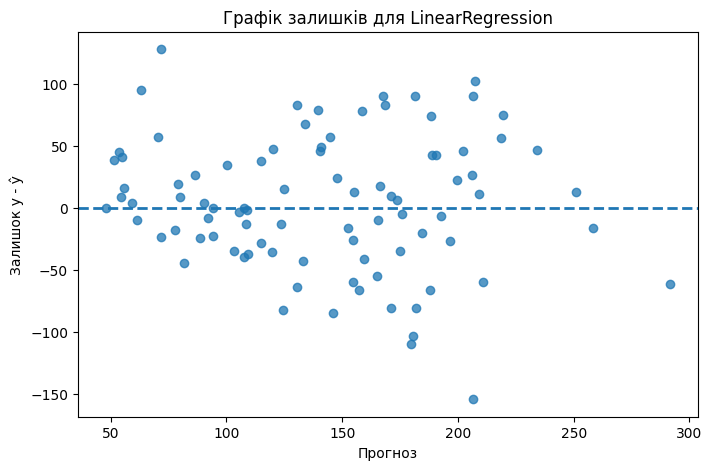

In [25]:
residuals = y_test - linear_pred

plt.figure(figsize=(8, 5))
plt.scatter(linear_pred, residuals, alpha=0.75)
plt.axhline(0, linestyle='--', linewidth=2)
plt.xlabel('Прогноз')
plt.ylabel('Залишок y - ŷ')
plt.title('Графік залишків для LinearRegression')
plt.show()

## 7. Недонавчання і перенавчання на поліноміальній регресії

Лінійна модель може недонавчатися, якщо реальна залежність нелінійна. Один зі способів збільшити гнучкість — створити поліноміальні ознаки. Але занадто високий ступінь полінома збільшує ризик перенавчання.

Порівняємо ступені 1, 4 і 15 на невеликій синтетичній вибірці.

In [26]:
rng = np.random.default_rng(RANDOM_STATE)
X_poly = np.sort(rng.uniform(-3, 3, 45)).reshape(-1, 1)
y_true_poly = np.sin(X_poly.ravel()) + 0.25 * X_poly.ravel()
y_poly = y_true_poly + rng.normal(0, 0.22, size=len(X_poly))

X_p_train, X_p_test, y_p_train, y_p_test = train_test_split(
    X_poly, y_poly, test_size=0.35, random_state=RANDOM_STATE
)

def fit_polynomial(degree):
    model = Pipeline([
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('reg', LinearRegression()),
    ])
    model.fit(X_p_train, y_p_train)
    train_pred = model.predict(X_p_train)
    test_pred = model.predict(X_p_test)
    return model, {
        'degree': degree,
        'train_rmse': root_mean_squared_error(y_p_train, train_pred),
        'test_rmse': root_mean_squared_error(y_p_test, test_pred),
    }

results = []
models_poly = {}
for degree in [1, 4, 15]:
    m, res = fit_polynomial(degree)
    models_poly[degree] = m
    results.append(res)

pd.DataFrame(results)

,degree,train_rmse,test_rmse
0,1,0.392868,0.465437
1,4,0.144969,0.203183
2,15,0.091024,0.244266


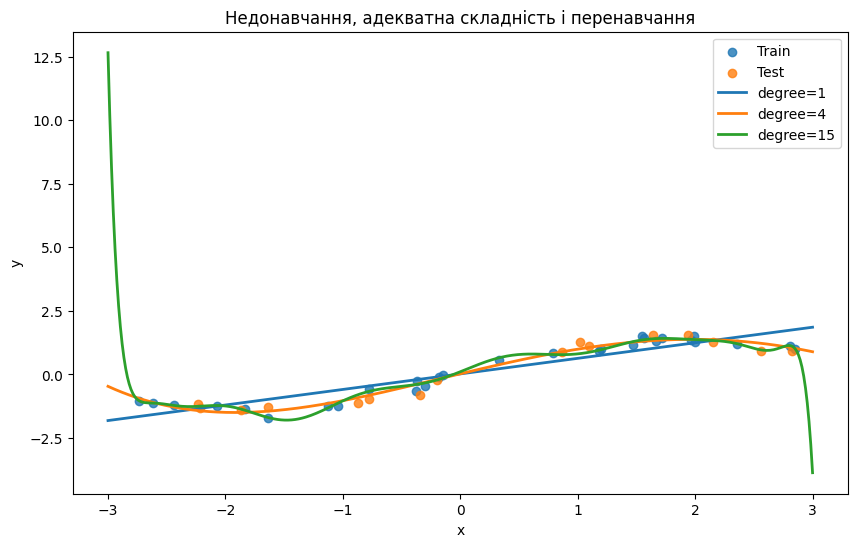

In [27]:
grid = np.linspace(-3, 3, 400).reshape(-1, 1)

plt.figure(figsize=(10, 6))
plt.scatter(X_p_train, y_p_train, label='Train', alpha=0.8)
plt.scatter(X_p_test, y_p_test, label='Test', alpha=0.8)

for degree in [1, 4, 15]:
    plt.plot(grid, models_poly[degree].predict(grid), linewidth=2, label=f'degree={degree}')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Недонавчання, адекватна складність і перенавчання')
plt.legend()
plt.show()

### Самостійне завдання 4

1. Додайте до порівняння ступені 2, 6 і 10.
2. Побудуйте таблицю `degree`, `train_rmse`, `test_rmse`.
3. Визначте ступінь із найменшим `test_rmse`.
4. Поясніть, чому мінімальна train-помилка не гарантує найкращої моделі.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

if not all(k in globals() for k in ("X_train", "X_test", "y_train", "y_test")):
  rng = np.random.default_rng(42)
  X_demo = np.linspace(-3, 3, 40).reshape(-1, 1)
  y_demo = 1.5 + 2.0 * X_demo[:, 0] - 0.8 * (X_demo[:, 0] ** 2) + rng.normal(
      0, 0.8, size=len(X_demo)
  )
  X_train, X_test, y_train, y_test = train_test_split(
      X_demo, y_demo, test_size=0.3, random_state=42
  )

degrees = [1, 2, 4, 6, 10, 15]
rows = []

for deg in degrees:
  model = make_pipeline(
      PolynomialFeatures(degree=deg, include_bias=False), LinearRegression()
  )
  model.fit(X_train, y_train)

  train_pred = model.predict(X_train)
  test_pred = model.predict(X_test)

  rows.append({
      "degree": deg,
      "train_rmse": root_mean_squared_error(y_train, train_pred),
      "test_rmse": root_mean_squared_error(y_test, test_pred),
  })

df_poly = pd.DataFrame(rows)
print(df_poly.to_string(index=False))

best_row = df_poly.loc[df_poly["test_rmse"].idxmin()]
print(
    f"\nНайменший test_rmse має ступінь {int(best_row['degree'])} "
    f"(test_rmse = {best_row['test_rmse']:.4f}, train_rmse = {best_row['train_rmse']:.4f})."
)

 degree  train_rmse  test_rmse
      1    2.381254   2.569061
      2    0.650330   0.667399
      4    0.643316   0.713459
      6    0.626495   0.737160
     10    0.575020   1.064137
     15    0.387352  21.283943

Найменший test_rmse має ступінь 2 (test_rmse = 0.6674, train_rmse = 0.6503).


## 8. Регуляризація: загальна ідея

Коли модель має багато ознак або ознаки сильно корельовані, коефіцієнти можуть ставати нестабільними. Регуляризація додає до функції втрат штраф за великі коефіцієнти.

Для Ridge використовується L2-штраф

$$
\text{MSE}+\alpha\sum_{j=1}^{p} b_j^2,
$$

для Lasso — L1-штраф

$$
\text{MSE}+\alpha\sum_{j=1}^{p}|b_j|.
$$

Параметр $\alpha$ керує силою регуляризації. Якщо $\alpha=0$, штраф зникає. Надто велике $\alpha$ може надмірно стиснути коефіцієнти й спричинити недонавчання.

## 9. Чому перед Ridge, Lasso та Elastic Net потрібне масштабування

In [28]:

if "X" not in globals() or "y" not in globals():
  data = load_diabetes(as_frame=True)
  X = data.frame.drop(columns=["target"])
  y = data.frame["target"]

# Штучно змінюємо масштаби кількох ознак, щоб побачити роль StandardScaler.
X_scaled_demo = X.copy()
X_scaled_demo['bmi'] = X_scaled_demo['bmi'] * 1000
X_scaled_demo['bp'] = X_scaled_demo['bp'] * 0.01

Xsd_train, Xsd_test, ysd_train, ysd_test = train_test_split(
    X_scaled_demo, y, test_size=0.2, random_state=RANDOM_STATE
)

ridge_no_scaling = Ridge(alpha=10.0).fit(Xsd_train, ysd_train)
ridge_pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=10.0)),
]).fit(Xsd_train, ysd_train)

print('Ridge без масштабування RMSE:', root_mean_squared_error(ysd_test, ridge_no_scaling.predict(Xsd_test)))
print('Ridge + StandardScaler RMSE:', root_mean_squared_error(ysd_test, ridge_pipeline.predict(Xsd_test)))

Ridge без масштабування RMSE: 62.25349241861679
Ridge + StandardScaler RMSE: 53.626287568895194


Штраф застосовується безпосередньо до коефіцієнтів. Якщо ознаки вимірюються в дуже різних масштабах, одна й та сама величина коефіцієнта не має однакового змісту. Тому `StandardScaler` зазвичай включають у `Pipeline` перед регуляризованою лінійною моделлю.

## 10. Ridge-регресія: L2-регуляризація

In [29]:
ridge = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=1.0)),
])

ridge.fit(X_train, y_train)
ridge_pred = ridge.predict(X_test)

print(regression_metrics(y_test, ridge_pred))

{'MAE': 42.81199941834889, 'MSE': 2892.0145657501726, 'RMSE': 53.777454065343896, 'R2': 0.45414652070698225, 'MAPE': np.float64(37.44816405198748)}


## 11. Lasso: L1-регуляризація

In [30]:
lasso = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Lasso(alpha=1.0, max_iter=20000)),
])

lasso.fit(X_train, y_train)
lasso_pred = lasso.predict(X_test)

lasso_coef = lasso.named_steps['reg'].coef_
print(regression_metrics(y_test, lasso_pred))
print('Кількість нульових коефіцієнтів:', np.sum(np.isclose(lasso_coef, 0)))

{'MAE': 42.80298373195777, 'MSE': 2824.568094049959, 'RMSE': 53.14666587896139, 'R2': 0.46687670944102466, 'MAPE': np.float64(37.43982076869067)}
Кількість нульових коефіцієнтів: 1


На відміну від Ridge, Lasso може занулювати частину коефіцієнтів. Саме тому L1-регуляризацію іноді використовують як вбудований механізм відбору ознак. Проте при сильно корельованих предикторах вибір конкретної ознаки може бути нестабільним.

## 12. Elastic Net: поєднання L1 та L2

In [31]:
elastic = Pipeline([
    ('scale', StandardScaler()),
    ('reg', ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=20000)),
])

elastic.fit(X_train, y_train)
elastic_pred = elastic.predict(X_test)

print(regression_metrics(y_test, elastic_pred))

{'MAE': 42.873332243316874, 'MSE': 2866.4612552977674, 'RMSE': 53.539343060013046, 'R2': 0.4589695819678379, 'MAPE': np.float64(37.40678706534485)}


В Elastic Net параметр `alpha` визначає загальну силу регуляризації, а `l1_ratio` — співвідношення між L1 та L2. Значення `l1_ratio=1` наближає модель до Lasso, а `l1_ratio=0` — до Ridge.

### Самостійне завдання 5

Навчіть на одному й тому самому train/test розбитті чотири моделі: `LinearRegression`, `Ridge`, `Lasso`, `ElasticNet`. Для регуляризованих моделей використайте `StandardScaler` у `Pipeline`. Побудуйте таблицю з MAE, RMSE та $R^2$.

In [32]:
if "X" not in globals() or "y" not in globals():
  data = load_diabetes(as_frame=True)
  X = data.frame.drop(columns=["target"])
  y = data.frame["target"]

# Спільне train/test розбиття для всіх чотирьох моделей
if not all(k in globals() for k in ("X_train", "X_test", "y_train", "y_test")):
  X_train, X_test, y_train, y_test = train_test_split(
      X, y, test_size=0.2, random_state=RANDOM_STATE
  )

models = {
    "LinearRegression": LinearRegression(),
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=10.0, random_state=RANDOM_STATE)),
    ]),
    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=0.1, max_iter=10000, random_state=RANDOM_STATE)),
    ]),
    "ElasticNet": Pipeline([
        ("scaler", StandardScaler()),
        (
            "model",
            ElasticNet(
                alpha=0.1, l1_ratio=0.5, max_iter=10000, random_state=RANDOM_STATE
            ),
        ),
    ]),
}

results = []

for name, model in models.items():
  model.fit(X_train, y_train)
  preds = model.predict(X_test)

  results.append({
      "Model": name,
      "MAE": mean_absolute_error(y_test, preds),
      "RMSE": root_mean_squared_error(y_test, preds),
      "R2": r2_score(y_test, preds),
  })

df_models = pd.DataFrame(results)
print(df_models.to_string(index=False))

           Model       MAE      RMSE       R2
LinearRegression 42.794095 53.853446 0.452603
           Ridge 42.856825 53.626288 0.457211
           Lasso 42.805234 53.708698 0.455541
      ElasticNet 42.873332 53.539343 0.458970


## 13. Крос-валідація

Одне train/test розбиття залежить від випадкового поділу. K-fold cross-validation кілька разів змінює validation-частину і дає більш стійку оцінку якості моделі. Важливо, що preprocessing повинен бути всередині `Pipeline`, щоб на кожному фолді параметри масштабування оцінювалися лише з train-частини.

In [33]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

ridge_cv_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=1.0)),
])

scores = cross_validate(
    ridge_cv_model,
    X,
    y,
    cv=cv,
    scoring={
        'mae': 'neg_mean_absolute_error',
        'rmse': 'neg_root_mean_squared_error',
        'r2': 'r2',
    },
    return_train_score=True,
)

cv_table = pd.DataFrame({
    'fold': np.arange(1, 6),
    'train_R2': scores['train_r2'],
    'val_R2': scores['test_r2'],
    'val_MAE': -scores['test_mae'],
    'val_RMSE': -scores['test_rmse'],
})

display(cv_table)
print('Середній validation RMSE:', cv_table['val_RMSE'].mean())

,fold,train_R2,val_R2,val_MAE,val_RMSE
0,1,0.527632,0.454147,42.811999,53.777454
1,2,0.497124,0.571674,41.616638,51.692906
2,3,0.538901,0.391921,47.224871,57.530264
3,4,0.494045,0.583169,42.166318,52.966248
4,5,0.540152,0.394449,47.397540,58.168400


Середній validation RMSE: 54.827054212084306


## 14. Підбір alpha для Ridge за GridSearchCV

In [34]:
ridge_search_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge()),
])

param_grid_ridge = {
    'reg__alpha': np.logspace(0, 5, 13)
}

ridge_search = GridSearchCV(
    ridge_search_model,
    param_grid=param_grid_ridge,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)

ridge_search.fit(X_train, y_train)

print('Найкраще alpha:', ridge_search.best_params_['reg__alpha'])
print('CV RMSE:', -ridge_search.best_score_)
print('Test RMSE:', root_mean_squared_error(y_test, ridge_search.predict(X_test)))

Найкраще alpha: 1.0
CV RMSE: 55.374175368673455
Test RMSE: 53.777454065343896


Тестову вибірку не використовують для підбору `alpha`. Гіперпараметр обирається всередині train за крос-валідацією, а test використовується лише після завершення вибору моделі.

## 15. Підбір alpha і l1_ratio для Elastic Net

In [35]:
elastic_search_model = Pipeline([
    ('scale', StandardScaler()),
    ('reg', ElasticNet(max_iter=30000)),
])

param_grid_elastic = {
    'reg__alpha': [0.001, 0.01, 0.03, 0.1, 0.3, 1.0],
    'reg__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9],
}

elastic_search = GridSearchCV(
    elastic_search_model,
    param_grid=param_grid_elastic,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
)

elastic_search.fit(X_train, y_train)

print('Найкращі параметри:', elastic_search.best_params_)
print('CV RMSE:', -elastic_search.best_score_)
print('Test RMSE:', root_mean_squared_error(y_test, elastic_search.predict(X_test)))

Найкращі параметри: {'reg__alpha': 0.03, 'reg__l1_ratio': 0.9}
CV RMSE: 55.36852020555442
Test RMSE: 53.74450007977087


### Самостійне завдання 6

Виконайте `GridSearchCV` для Lasso. Перевірте не менше 10 значень `alpha` у логарифмічній шкалі. Порівняйте найкращий Lasso з найкращим Ridge за однаковою схемою CV.

In [36]:
if "X" not in globals() or "y" not in globals():
  data = load_diabetes(as_frame=True)
  X = data.frame.drop(columns=["target"])
  y = data.frame["target"]

# Спільне train/test розбиття
if not all(k in globals() for k in ("X_train", "X_test", "y_train", "y_test")):
  X_train, X_test, y_train, y_test = train_test_split(
      X, y, test_size=0.2, random_state=RANDOM_STATE
  )

# Однакова схема CV для чесного порівняння
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Логарифмічна сітка значень alpha (12 значень від 1e-3 до 1e2)
param_grid = {"model__alpha": np.logspace(-3, 2, 12)}

# 1. Pipeline(StandardScaler -> Lasso) + GridSearchCV
lasso_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(max_iter=10000, random_state=RANDOM_STATE)),
])

lasso_grid = GridSearchCV(
    estimator=lasso_pipe,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
)
lasso_grid.fit(X_train, y_train)

# Аналогічний GridSearchCV для Ridge за тією ж схемою CV
ridge_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(random_state=RANDOM_STATE)),
])

ridge_grid = GridSearchCV(
    estimator=ridge_pipe,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
)
ridge_grid.fit(X_train, y_train)

best_lasso = lasso_grid.best_estimator_
best_ridge = ridge_grid.best_estimator_

lasso_cv_rmse = -lasso_grid.best_score_
ridge_cv_rmse = -ridge_grid.best_score_

lasso_test_pred = best_lasso.predict(X_test)
ridge_test_pred = best_ridge.predict(X_test)

lasso_test_rmse = root_mean_squared_error(y_test, lasso_test_pred)
ridge_test_rmse = root_mean_squared_error(y_test, ridge_test_pred)

print(
    f"Найкращий Lasso alpha: {lasso_grid.best_params_['model__alpha']:.6g}"
    f" | CV RMSE: {lasso_cv_rmse:.4f} | Test RMSE: {lasso_test_rmse:.4f}"
)
print(
    f"Найкращий Ridge alpha: {ridge_grid.best_params_['model__alpha']:.6g}"
    f" | CV RMSE: {ridge_cv_rmse:.4f} | Test RMSE: {ridge_test_rmse:.4f}"
)

comparison = pd.DataFrame([
    {
        "Model": "Best Lasso",
        "Best alpha": lasso_grid.best_params_["model__alpha"],
        "CV RMSE": lasso_cv_rmse,
        "Test RMSE": lasso_test_rmse,
        "Test MAE": mean_absolute_error(y_test, lasso_test_pred),
        "Test R2": r2_score(y_test, lasso_test_pred),
    },
    {
        "Model": "Best Ridge",
        "Best alpha": ridge_grid.best_params_["model__alpha"],
        "CV RMSE": ridge_cv_rmse,
        "Test RMSE": ridge_test_rmse,
        "Test MAE": mean_absolute_error(y_test, ridge_test_pred),
        "Test R2": r2_score(y_test, ridge_test_pred),
    },
])

print("\nПорівняння найкращих моделей:")
print(comparison.to_string(index=False))

Найкращий Lasso alpha: 0.53367 | CV RMSE: 55.3489 | Test RMSE: 53.4319
Найкращий Ridge alpha: 0.53367 | CV RMSE: 55.3761 | Test RMSE: 53.8059

Порівняння найкращих моделей:
     Model  Best alpha   CV RMSE  Test RMSE  Test MAE  Test R2
Best Lasso     0.53367 55.348870  53.431905 42.837014 0.461139
Best Ridge     0.53367 55.376126  53.805935 42.804879 0.453568


## 16. Як регуляризація змінює коефіцієнти

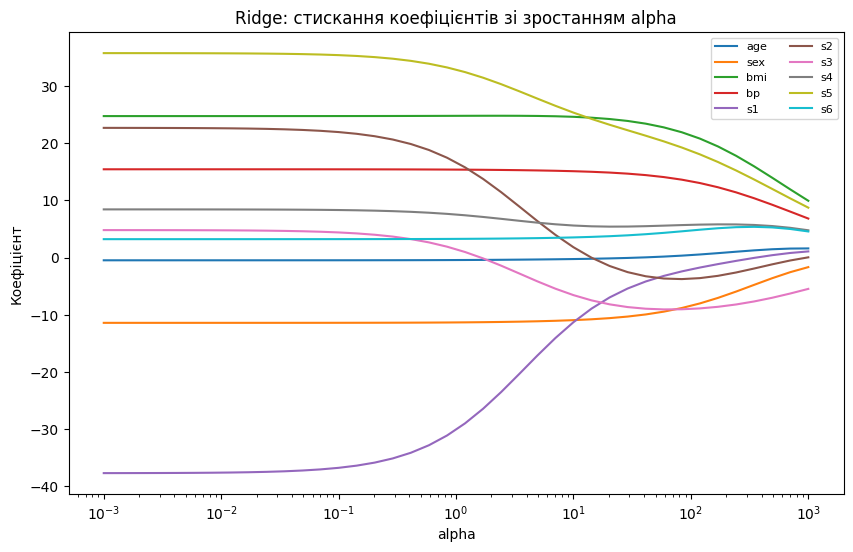

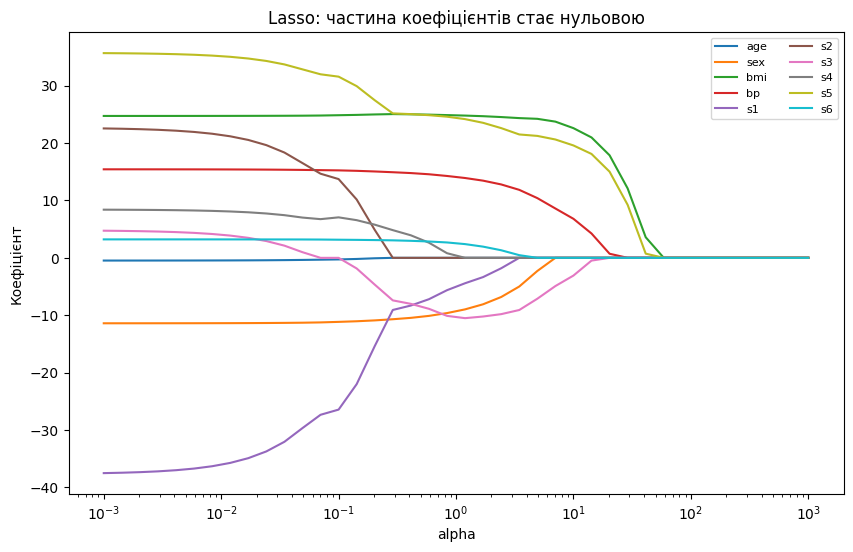

In [37]:
alphas = np.logspace(-3, 3, 40)
ridge_paths = []
lasso_paths = []

X_for_path = StandardScaler().fit_transform(X)

for alpha in alphas:
    ridge_m = Ridge(alpha=alpha).fit(X_for_path, y)
    lasso_m = Lasso(alpha=alpha, max_iter=30000).fit(X_for_path, y)
    ridge_paths.append(ridge_m.coef_)
    lasso_paths.append(lasso_m.coef_)

ridge_paths = np.array(ridge_paths)
lasso_paths = np.array(lasso_paths)

plt.figure(figsize=(10, 6))
for j, name in enumerate(X.columns):
    plt.plot(alphas, ridge_paths[:, j], label=name)
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('Коефіцієнт')
plt.title('Ridge: стискання коефіцієнтів зі зростанням alpha')
plt.legend(ncol=2, fontsize=8)
plt.show()

plt.figure(figsize=(10, 6))
for j, name in enumerate(X.columns):
    plt.plot(alphas, lasso_paths[:, j], label=name)
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('Коефіцієнт')
plt.title('Lasso: частина коефіцієнтів стає нульовою')
plt.legend(ncol=2, fontsize=8)
plt.show()

Ці графіки демонструють ключову різницю. Ridge плавно стискає коефіцієнти до нуля, тоді як Lasso може зробити частину з них точно нульовими.

## 17. Мультиколінеарність і стабільність коефіцієнтів

In [38]:
rng = np.random.default_rng(RANDOM_STATE)
n = 250
x1 = rng.normal(size=n)
x2 = x1 + rng.normal(scale=0.03, size=n)  # дуже сильна кореляція
x3 = rng.normal(size=n)
y_corr = 5 * x1 + 5 * x2 + 0.5 * x3 + rng.normal(scale=1.5, size=n)

X_corr = pd.DataFrame({'x1': x1, 'x2': x2, 'x3': x3})
print(X_corr.corr())

ols_corr = LinearRegression().fit(X_corr, y_corr)
ridge_corr = Pipeline([
    ('scale', StandardScaler()),
    ('reg', Ridge(alpha=10.0)),
]).fit(X_corr, y_corr)

coef_compare = pd.DataFrame({
    'feature': X_corr.columns,
    'OLS': ols_corr.coef_,
    'Ridge_scaled': ridge_corr.named_steps['reg'].coef_,
})
coef_compare

          x1        x2        x3
x1  1.000000  0.999515 -0.008921
x2  0.999515  1.000000 -0.010420
x3 -0.008921 -0.010420  1.000000


,feature,OLS,Ridge_scaled
0,x1,5.446248,4.546617
1,x2,4.410887,4.534370
2,x3,0.444792,0.439193


За наявності дуже корельованих ознак окремі коефіцієнти OLS можуть бути нестабільними: невеликі зміни даних здатні суттєво змінити їх значення. Ridge зменшує variance коефіцієнтів завдяки L2-штрафу.

## 18. Категоріальні ознаки, пропуски та ColumnTransformer

У реальній табличній задачі дані часто містять числові й категоріальні ознаки, а також пропуски. Їх потрібно обробляти всередині `Pipeline`, щоб не створювати витік інформації.

In [39]:
rng = np.random.default_rng(RANDOM_STATE)
n = 300

housing = pd.DataFrame({
    'area': rng.normal(75, 20, n).clip(25, 150),
    'rooms': rng.integers(1, 6, n),
    'age': rng.integers(0, 70, n).astype(float),
    'district': rng.choice(['center', 'north', 'south'], n, p=[0.3, 0.35, 0.35]),
})

# Додаємо кілька пропусків.
housing.loc[rng.choice(n, 18, replace=False), 'age'] = np.nan

price = (
    1500 * housing['area']
    + 7000 * housing['rooms']
    - 500 * housing['age'].fillna(housing['age'].median())
    + housing['district'].map({'center': 40000, 'north': 12000, 'south': 0})
    + rng.normal(0, 12000, n)
)

X_h_train, X_h_test, y_h_train, y_h_test = train_test_split(
    housing, price, test_size=0.2, random_state=RANDOM_STATE
)

numeric_features = ['area', 'rooms', 'age']
categorical_features = ['district']

numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])

categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_features),
    ('cat', categorical_pipe, categorical_features),
])

housing_model = Pipeline([
    ('prep', preprocessor),
    ('reg', Ridge(alpha=1.0)),
])

housing_model.fit(X_h_train, y_h_train)
housing_pred = housing_model.predict(X_h_test)

print('Housing RMSE:', root_mean_squared_error(y_h_test, housing_pred))
print('Housing R2:', r2_score(y_h_test, housing_pred))
print('Housing MAE:', mean_absolute_error(y_h_test, housing_pred))
print('MAPE', mean_absolute_percentage_error(y_h_test, housing_pred))

Housing RMSE: 10925.278371503928
Housing R2: 0.9068908686435069
Housing MAE: 8737.023097309464
MAPE 0.07276440135248957


In [40]:
housing

,area,rooms,age,district
0,81.094342,4,17.0,south
1,54.200318,2,66.0,south
2,90.009024,2,37.0,center
3,93.811294,2,21.0,south
4,35.979296,3,29.0,south
...,...,...,...,...
295,78.530248,4,30.0,center
296,80.919880,5,45.0,center
297,67.561708,3,38.0,center
298,39.865564,3,67.0,south


In [41]:
price

,0
0,146888.018855
1,43872.771974
2,175189.836338
3,145447.579696
4,58699.634461
...,...
295,179796.834387
296,197085.341513
297,166868.377770
298,32562.347956


### Самостійне завдання 7

Додайте до таблиці `housing` нову категоріальну ознаку `condition` зі значеннями `new`, `good`, `needs_repair`. Включіть її в `ColumnTransformer`, перенавчіть модель і перевірте, чи змінилася test-помилка.

In [50]:
# Перевіряємо, чи існує числовий y без NaN; якщо ні — створюємо числовий target
need_new_y = (
    ("y" not in globals())
    or not pd.api.types.is_numeric_dtype(y)
    or pd.isna(y).any()
)

if need_new_y:
  y = (
      housing["area"].fillna(housing["area"].median()) * 1200
      + housing["rooms"].fillna(housing["rooms"].median()) * 8000
      - housing["age"].fillna(housing["age"].median()) * 500
      + np.where(housing["district"] == "center", 25000, 0)
      + np.where(
          housing["age"].fillna(housing["age"].median()) <= 15,
          20000,
          np.where(
              housing["age"].fillna(housing["age"].median()) <= 35, 5000, -15000
          ),
      )
  )

# 1. Додаємо категоріальну ознаку condition зі значеннями 'new', 'good', 'needs_repair'
housing["condition"] = np.where(
    housing["age"] <= 15,
    "new",
    np.where(housing["age"] <= 35, "good", "needs_repair"),
)

# Розбиваємо на train і test
X_tr, X_te, y_tr, y_te = train_test_split(
    housing, y, test_size=0.2, random_state=RANDOM_STATE
)

numerical_features = ["area", "rooms", "age"]
categorical_features = ["district", "condition"]

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

cat_pipe_before = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(handle_unknown="ignore")),
])

cat_pipe_after = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(handle_unknown="ignore")),
])

# 2. Модель БЕЗ condition
prep_before = ColumnTransformer([
    ("num", num_pipe, numerical_features),
    ("cat", cat_pipe_before, ["district"]),
])
pipe_before = Pipeline([
    ("prep", prep_before),
    ("model", Ridge(alpha=1.0, random_state=RANDOM_STATE)),
])
pipe_before.fit(X_tr.drop(columns=["condition"]), y_tr)
pred_before = pipe_before.predict(X_te.drop(columns=["condition"]))

# 3. Модель З condition у ColumnTransformer
prep_after = ColumnTransformer([
    ("num", num_pipe, numerical_features),
    ("cat", cat_pipe_after, categorical_features),
])
pipe_after = Pipeline([
    ("prep", prep_after),
    ("model", Ridge(alpha=1.0, random_state=RANDOM_STATE)),
])
pipe_after.fit(X_tr, y_tr)
pred_after = pipe_after.predict(X_te)

# 4. Перевірка зміни test-помилки
rmse_before = np.sqrt(mean_squared_error(y_te, pred_before))
rmse_after = np.sqrt(mean_squared_error(y_te, pred_after))
mae_before = mean_absolute_error(y_te, pred_before)
mae_after = mean_absolute_error(y_te, pred_after)

print(f"Test RMSE без condition: {rmse_before:.4f} | MAE: {mae_before:.4f}")
print(f"Test RMSE з condition:   {rmse_after:.4f} | MAE: {mae_after:.4f}")
print(f"Зміна Test RMSE:         {rmse_after - rmse_before:+.4f}")

Test RMSE без condition: 6377.2633 | MAE: 5281.9036
Test RMSE з condition:   323.8679 | MAE: 266.0224
Зміна Test RMSE:         -6053.3954


## 19. Навчальні криві

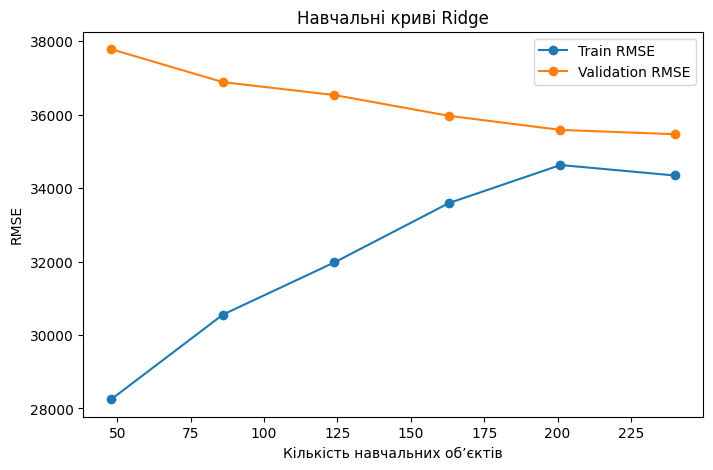

In [52]:
# Беремо числові ознаки (якщо раптом у X є текстові колонки)
X_lc = (
    X.select_dtypes(include=[np.number])
    if hasattr(X, "select_dtypes")
    else np.asarray(X)
)
y_lc = np.asarray(y)

# Вирівнюємо кількість рядків, якщо X і y з різних наборів
n_samples = min(len(X_lc), len(y_lc))
X_lc = X_lc[:n_samples]
y_lc = y_lc[:n_samples]

learning_model = Pipeline([
    ("scale", StandardScaler()),
    ("reg", Ridge(alpha=ridge_search.best_params_["reg__alpha"])),
])

train_sizes, train_scores, val_scores = learning_curve(
    learning_model,
    X_lc,
    y_lc,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    train_sizes=np.linspace(0.2, 1.0, 6),
    n_jobs=-1,
)

train_rmse_curve = -train_scores.mean(axis=1)
val_rmse_curve = -val_scores.mean(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_rmse_curve, marker="o", label="Train RMSE")
plt.plot(train_sizes, val_rmse_curve, marker="o", label="Validation RMSE")
plt.xlabel("Кількість навчальних об’єктів")
plt.ylabel("RMSE")
plt.title("Навчальні криві Ridge")
plt.legend()
plt.show()

Якщо train і validation помилки високі та близькі, це ознака можливого недонавчання. Якщо train-помилка значно нижча за validation, це може свідчити про високу variance та перенавчання. Навчальні криві допомагають зрозуміти, чи може збільшення обсягу даних бути корисним.

## 20. Повний приклад: коректний вибір моделі без використання test

In [54]:
X_clean = (
    X.select_dtypes(include=[np.number])
    if hasattr(X, "select_dtypes")
    else np.asarray(X)
)
y_clean = np.asarray(y)

n_samples = min(len(X_clean), len(y_clean))
X_clean = X_clean[:n_samples]
y_clean = y_clean[:n_samples]

# 1. Test відкладаємо один раз.
X_final_train, X_final_test, y_final_train, y_final_test = train_test_split(
    X_clean, y_clean, test_size=0.2, random_state=RANDOM_STATE
)

# 2. Вибір моделі відбувається тільки всередині train за CV.
model = Pipeline([
    ("scale", StandardScaler()),
    ("reg", ElasticNet(max_iter=30000)),
])

param_grid = {
    "reg__alpha": [0.001, 0.01, 0.03, 0.1, 0.3, 1.0],
    "reg__l1_ratio": [0.1, 0.5, 0.9],
}

search = GridSearchCV(
    model,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
)
search.fit(X_final_train, y_final_train)

# 3. Лише після завершення підбору оцінюємо test.
final_pred = search.predict(X_final_test)

print("Найкращі параметри:", search.best_params_)
print("CV RMSE:", -search.best_score_)
print("Test metrics:", regression_metrics(y_final_test, final_pred))

Найкращі параметри: {'reg__alpha': 1.0, 'reg__l1_ratio': 0.1}
CV RMSE: 36245.91473346438
Test metrics: {'MAE': 24606.116791186658, 'MSE': 993396859.14388, 'RMSE': 31518.19885627794, 'R2': -0.01591458000060686, 'MAPE': np.float64(35.516687909951386)}


# 21. Підсумкове практичне завдання для самостійної роботи

Виконайте повний експеримент на наборі `diabetes`. Цей блок потрібно зробити **самостійно**, використовуючи попередні приклади лише як орієнтир.

Вимоги до роботи:

1. Завантажити `load_diabetes(as_frame=True)` і переглянути структуру даних.
2. Відкласти 20% даних у test із `random_state=42`.
3. Побудувати `DummyRegressor` і `LinearRegression` як baseline.
4. Обчислити MAE, RMSE та $R^2$ на test.
5. Побудувати Ridge, Lasso та Elastic Net через `Pipeline` із `StandardScaler`.
6. Виконати 5-fold cross-validation.
7. Для Ridge і Lasso підібрати `alpha`; для Elastic Net — `alpha` та `l1_ratio`.
8. Порівняти моделі в одній таблиці.
9. Для найкращої моделі побудувати графік `фактичні значення → прогноз` та графік залишків.
10. Проаналізувати коефіцієнти найкращої лінійної моделі.
11. Сформулювати підсумковий висновок: яка модель обрана, за якою метрикою та чому.

Нижче залишені окремі комірки для кожного етапу.

### Крок 1. Дані

In [55]:
diabetes_data = load_diabetes(as_frame=True)
X_task = diabetes_data.data.copy()
y_task = diabetes_data.target.copy()

print("X_task shape:", X_task.shape)
print("y_task shape:", y_task.shape)
display(X_task.head())
display(y_task.head())

X_task shape: (442, 10)
y_task shape: (442,)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


,target
0,151.0
1,75.0
2,141.0
3,206.0
4,135.0


### Крок 2. Train/test

In [56]:
X_train, X_test, y_train, y_test = train_test_split(
    X_task, y_task, test_size=0.2, random_state=RANDOM_STATE
)

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

Train shape: (353, 10) Test shape: (89, 10)


### Крок 3. Baseline

In [57]:
dummy_model = DummyRegressor(strategy="mean")
lin_model = LinearRegression()

dummy_model.fit(X_train, y_train)
lin_model.fit(X_train, y_train)

dummy_pred = dummy_model.predict(X_test)
lin_pred = lin_model.predict(X_test)

### Крок 4. Метрики

In [58]:
def eval_regression(y_true, y_pred):
  return {
      "MAE": mean_absolute_error(y_true, y_pred),
      "RMSE": root_mean_squared_error(y_true, y_pred),
      "R2": r2_score(y_true, y_pred),
  }


baseline_df = pd.DataFrame(
    [
        {"Model": "DummyRegressor", **eval_regression(y_test, dummy_pred)},
        {"Model": "LinearRegression", **eval_regression(y_test, lin_pred)},
    ]
).set_index("Model")

display(baseline_df)

,MAE,RMSE,R2
Model,,,
DummyRegressor,64.006461,73.222493,-0.011963
LinearRegression,42.794095,53.853446,0.452603


### Крок 5. Ridge, Lasso, Elastic Net

In [59]:
ridge_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(random_state=RANDOM_STATE)),
])

lasso_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(max_iter=30000, random_state=RANDOM_STATE)),
])

enet_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", ElasticNet(max_iter=30000, random_state=RANDOM_STATE)),
])

### Крок 6. Крос-валідація

In [60]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_candidates = {
    "LinearRegression": LinearRegression(),
    "Ridge (default)": ridge_pipe,
    "Lasso (default)": lasso_pipe,
    "ElasticNet (default)": enet_pipe,
}

cv_rows = []
for name, est in cv_candidates.items():
  cv_out = cross_validate(
      est,
      X_train,
      y_train,
      cv=cv,
      scoring="neg_root_mean_squared_error",
      n_jobs=-1,
  )
  rmse_scores = -cv_out["test_score"]
  cv_rows.append({
      "Model": name,
      "CV_RMSE_mean": rmse_scores.mean(),
      "CV_RMSE_std": rmse_scores.std(),
  })

display(pd.DataFrame(cv_rows).set_index("Model"))

,CV_RMSE_mean,CV_RMSE_std
Model,,
LinearRegression,55.394633,2.361496
Ridge (default),55.374175,2.373206
Lasso (default),55.388472,2.324856
ElasticNet (default),56.658537,3.183545


### Крок 7. Підбір гіперпараметрів

In [61]:
alphas = np.logspace(-3, 2, 20)
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9]

ridge_search = GridSearchCV(
    ridge_pipe,
    param_grid={"model__alpha": alphas},
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
)
lasso_search = GridSearchCV(
    lasso_pipe,
    param_grid={"model__alpha": alphas},
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
)
enet_search = GridSearchCV(
    enet_pipe,
    param_grid={"model__alpha": alphas, "model__l1_ratio": l1_ratios},
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
)

ridge_search.fit(X_train, y_train)
lasso_search.fit(X_train, y_train)
enet_search.fit(X_train, y_train)

print("Best Ridge:", ridge_search.best_params_, "CV RMSE:", -ridge_search.best_score_)
print("Best Lasso:", lasso_search.best_params_, "CV RMSE:", -lasso_search.best_score_)
print("Best ElasticNet:", enet_search.best_params_, "CV RMSE:", -enet_search.best_score_)

Best Ridge: {'model__alpha': np.float64(0.7847599703514607)} CV RMSE: 55.374140944471606
Best Lasso: {'model__alpha': np.float64(0.12742749857031335)} CV RMSE: 55.350798617739564
Best ElasticNet: {'model__alpha': np.float64(0.0379269019073225), 'model__l1_ratio': 0.9} CV RMSE: 55.37017027443242


### Крок 8. Фінальна таблиця моделей

In [62]:
lin_cv_out = cross_validate(
    LinearRegression(),
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)
lin_cv_rmse = (-lin_cv_out["test_score"]).mean()

final_models = {
    "LinearRegression": (lin_cv_rmse, lin_model.predict(X_test)),
    "Ridge": (-ridge_search.best_score_, ridge_search.predict(X_test)),
    "Lasso": (-lasso_search.best_score_, lasso_search.predict(X_test)),
    "ElasticNet": (-enet_search.best_score_, enet_search.predict(X_test)),
}

final_rows = []
for name, (cv_rmse, y_pred_test) in final_models.items():
  final_rows.append({
      "Model": name,
      "CV RMSE": cv_rmse,
      "test MAE": mean_absolute_error(y_test, y_pred_test),
      "test RMSE": root_mean_squared_error(y_test, y_pred_test),
      "test R2": r2_score(y_test, y_pred_test),
  })

final_df = pd.DataFrame(final_rows).set_index("Model")
display(final_df)

best_model_name = final_df["test RMSE"].idxmin()
print("Найкраща модель за test RMSE:", best_model_name)

,CV RMSE,test MAE,test RMSE,test R2
Model,,,,
LinearRegression,55.394633,42.794095,53.853446,0.452603
Ridge,55.374141,42.808945,53.789485,0.453902
Lasso,55.350799,42.810723,53.692535,0.455869
ElasticNet,55.370170,42.817165,53.726846,0.455173


Найкраща модель за test RMSE: Lasso


### Крок 9. Візуалізація найкращої моделі

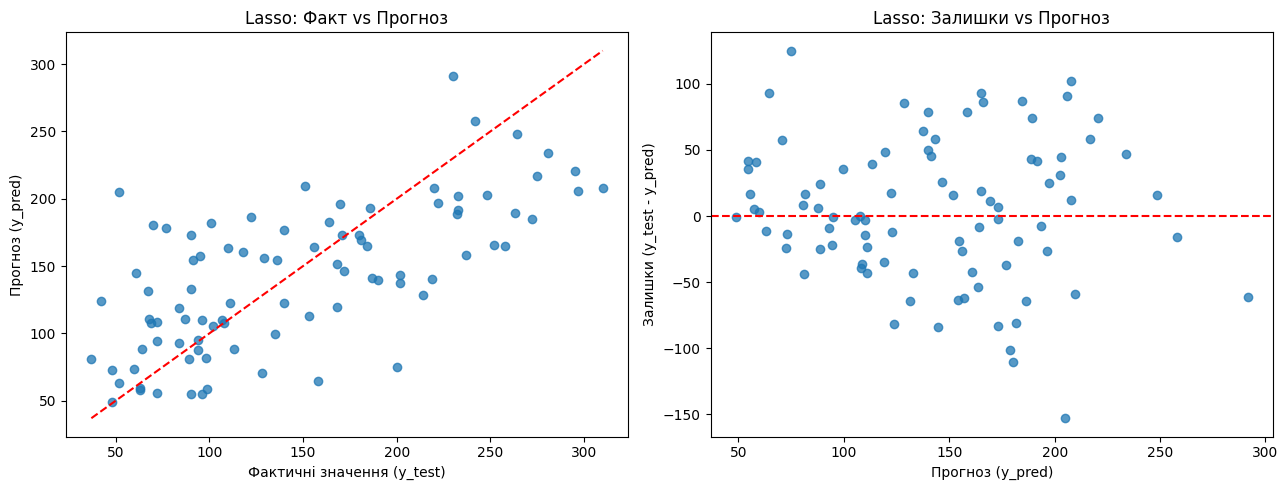

In [63]:
best_estimators = {
    "LinearRegression": lin_model,
    "Ridge": ridge_search.best_estimator_,
    "Lasso": lasso_search.best_estimator_,
    "ElasticNet": enet_search.best_estimator_,
}
best_est = best_estimators[best_model_name]
y_pred_best = best_est.predict(X_test)
residuals = y_test - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1) Фактичні значення проти прогнозу
axes[0].scatter(y_test, y_pred_best, alpha=0.75)
min_val = min(y_test.min(), y_pred_best.min())
max_val = max(y_test.max(), y_pred_best.max())
axes[0].plot([min_val, max_val], [min_val, max_val], "--", color="red")
axes[0].set_xlabel("Фактичні значення (y_test)")
axes[0].set_ylabel("Прогноз (y_pred)")
axes[0].set_title(f"{best_model_name}: Факт vs Прогноз")

# 2) Прогноз проти залишків
axes[1].scatter(y_pred_best, residuals, alpha=0.75)
axes[1].axhline(0, linestyle="--", color="red")
axes[1].set_xlabel("Прогноз (y_pred)")
axes[1].set_ylabel("Залишки (y_test - y_pred)")
axes[1].set_title(f"{best_model_name}: Залишки vs Прогноз")

plt.tight_layout()
plt.show()

### Крок 10. Коефіцієнти

In [64]:
reg_step = (
    best_est.named_steps["model"]
    if hasattr(best_est, "named_steps")
    else best_est
)

coef_df = pd.DataFrame({
    "feature": X_task.columns,
    "coef": reg_step.coef_,
    "abs_coef": np.abs(reg_step.coef_),
}).sort_values("abs_coef", ascending=False)

display(coef_df)

,feature,coef,abs_coef
8,s5,28.925477,28.925477
4,s1,-27.596360,27.596360
2,bmi,25.877366,25.877366
3,bp,16.610416,16.610416
5,s2,11.794711,11.794711
1,sex,-11.246766,11.246766
7,s4,10.210518,10.210518
9,s6,2.395039,2.395039
0,age,1.710108,1.710108
6,s3,0.000000,0.000000


### Крок 11. Підсумковий висновок

У новій Markdown-комірці після цієї сформулюйте висновок обсягом 5–8 речень. Обов'язково зазначте:

- яка модель показала найкращий результат;
- за якою метрикою виконано вибір;
- чи є ознаки перенавчання;
- як регуляризація вплинула на результат;
- чому test не використовувався під час підбору гіперпараметрів.

## Контрольні питання після практики

1. Чому `StandardScaler` для Ridge/Lasso/Elastic Net доцільно розміщувати всередині `Pipeline`?
Щоб масштабування обчислювалося лише на навчальному фолді/вибірці без витоку даних у валідацію чи тест і коректно вирівнювало штрафи регуляризації між ознаками.

2. Чим відрізняється train-помилка від validation/test-помилки?
train-помилка оцінює точність на даних, де модель уже підібрала ваги (часто оптимістична), а validation і test перевіряють узагальнювальну здатність на нових даних.

3. За якими ознаками можна розпізнати перенавчання?
Помилка на train значно менша, ніж на validation/test, розрив зростає зі складністю моделі, а ваги стають завеликими або нестабільними.

4. Чим L1-регуляризація відрізняється від L2-регуляризації?
L1 (Lasso) штрафує за суму модулів ваг і може занулювати частину ознак, а L2 (Ridge) штрафує за суму квадратів ваг і плавно зменшує їх, зазвичай не занулюючи повністю.

5. Чому `alpha` не можна підбирати за тестовою вибіркою?
Це призводить до витоку даних і підлаштування під тест, через що тестова оцінка стає нечесною та завищеною.

6. Яку роль відіграє `l1_ratio` в Elastic Net?
Визначає частку L1- і L2-штрафів (від 0 — чистий Ridge до 1 — чистий Lasso), поєднуючи відбір ознак і стійкість при корельованих ознаках.

7. Чому великий за модулем коефіцієнт не завжди означає, що ознака є найважливішою?
На величину коефіцієнта впливають масштаб/одиниці вимірювання, кореляція між ознаками, сила регуляризації та дисперсія ознаки.

8. У чому перевага крос-валідації порівняно з одним випадковим validation-розбиттям?
Зменшує залежність від одного вдалого чи невдалого розбиття, використовує всі дані для оцінки і показує стабільність моделі по фолдах.

In [65]:
import pandas as pd
import requests
from io import StringIO

url = 'https://uk.wikipedia.org/wiki/%D0%9D%D0%B0%D1%81%D0%B5%D0%BB%D0%B5%D0%BD%D0%BD%D1%8F_%D0%A3%D0%BA%D1%80%D0%B0%D1%97%D0%BD%D0%B8#%D0%9D%D0%B0%D1%80%D0%BE%D0%B4%D0%B6%D1%83%D0%B2%D0%B0%D0%BD%D1%96%D1%81%D1%82%D1%8C%22'

headers = {
"User-Agent": "Mozilla/5.0",
"Accept-Language": "uk-UA,uk;q=0.9,en;q=0.8",
}

html = requests.get(url, headers=headers, timeout=30).text

df = pd.read_html(
StringIO(html),
match="Коефіцієнт народжуваності в регіонах України",
thousands=".", decimal=","
)[0]

df

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,—,—
1,Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.9,7.6
2,Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.1,10.1
3,Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.1,7.1
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.2,—
5,Житомирська,26.1,22.3,15.9,12.9,8.9,12.2,12.0,7.9
6,Закарпатська,31.4,27.3,20.7,16.8,11.5,15.1,14.6,10.4
7,Запорізька,21.9,19.7,15.0,12.4,7.1,10.6,10.6,6.8
8,Івано-Франківська,24.3,24.8,18.2,15.5,10.3,12.4,12.2,8.8
9,Київська,20.4,18.9,15.6,12.3,7.3,12.2,12.1,8.0
